# Working with an AI coding assistant

Many people process data with the help of an AI coding assistant that can run commands in
a terminal. This notebook is for that reader: it gives you the prompts to paste, so that the
assistant installs the package, runs the documented commands, and asks you for every setting
the processing needs instead of choosing one for you.

**What you will learn**

- what such an assistant can do for you here, and what stays your responsibility;
- a first prompt that makes it read the documentation before it touches anything;
- the questions it must ask you before it processes your data, and why each one matters;
- how to tell it about data your PI or campaign team has already processed, and what it should
  do with those files;
- prompts for learning the procedures, for checking a result, and for working safely.

**What data:** none. The few code cells print the package's version and its own command
help, and write the question checklist into a temporary folder.

Section 7 builds a small
synthetic (demo) data set in memory to show what to look for in an output file. Nothing is downloaded and no
probe file is read.

**Before this:** [06_read_products](06_read_products.ipynb) (Reading the output files). **Next:** [08_ai_assistant_with_your_own_data](08_ai_assistant_with_your_own_data.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

## 1. What the assistant can do, and what it cannot

**It can** read this repository's README, the documentation in `docs/` and these notebooks;
install the package into a virtual environment; run the documented commands
(`arrayprobe run`, `arrayprobe make-tas-file`, `arrayprobe provenance`, `arrayprobe compare`
and the others the help lists); read the `.call` file written beside every output; and explain
what it ran.

**It cannot** know your instrument, your campaign or your science. Which probe you flew, which
processing rules suit your clouds, where the aircraft's airspeed record is, which seconds you
care about: these are your answers, and a guess from the assistant looks just as tidy on screen
as a real answer. The package helps here, because it refuses to guess the settings that matter:
a run with no processing rules named, no engine named, or (on the default engine) no airspeed
file stops with a message. Let the assistant hit that wall and ask you; do not let it fill the
gap with a plausible value.

**You stay responsible** for the settings and for the science. The assistant runs commands; it
does not take the decisions.

The cell below checks that the package is installed and says which engine a run gets when
none is named. If the assistant has installed the package for you, this is a quick way to see
that it worked.

In [1]:
# Launch guard: the cells below reach examples/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("examples").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/1_getting_started/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import arrayprobe

print("arrayprobe version:", arrayprobe.__version__)
print("default engine:    ", arrayprobe.engine().name)

arrayprobe version: 0.1.0
default engine:     3.5


## 2. The first prompt

Open a terminal in the root folder of this repository, start your assistant there, and paste
this. It asks for reading before doing, and for a question before every choice.

```text
I want to process optical array probe data with the arrayprobe package in this folder.
Before you run anything:
1. Read README.md, docs/01-installation.md, docs/06-configuration.md and
   docs/27-choosing-an-engine.md, and the notebooks in examples/1_getting_started/.
2. Tell me in a few sentences what the package does and which commands you will use.
3. Ask me before you install anything. Then install it into a virtual environment in
   this folder, exactly as docs/01-installation.md says, and show me the commands.
4. Run the start-here example in examples/start_here/README.md (a synthetic file;
   no real data) and show me the last lines of its output.
5. Do not choose any setting for my own data. When the package needs a setting,
   ask me, and tell me where in the documentation that setting is explained.
Only use commands and options that the documentation or `--help` shows. If you are
not sure a command exists, run it with --help first and tell me what it says.
```

The last two lines matter most. An assistant can invent an option that sounds right; asking it
to confirm each command with `--help` gives you a check you can see. The cell below prints the
start of the package's own command list, the same thing the assistant should be reading.

In [2]:
import subprocess
import sys

result = subprocess.run([sys.executable, "-m", "arrayprobe", "--help"],
                        capture_output=True, text=True, check=True)
lines = result.stdout.splitlines()
for line in lines[:14]:
    print(line)
print(f"... ({len(lines)} lines in all)")

usage: arrayprobe [-h] [--version] [--quiet | --verbose]
                  {run,reprocess,combine,compare,gallery,inventory,check-counts,triage,triage-recheck,triage-agreement,provenance,diode-masks,validate,view,intarr-threshold,attributed,make-demo-flight,make-tas-file,tas-from-nasa-ames,engines,tune,soda2,reproduce-report}
                  ...

To process data, use `arrayprobe run <config.toml>`: it runs every stage on
the engine the file names ([run].engine, required; use "3.5", UIOPS v3.5, for
new data; examples/configs/ has configs). To run one stage at a time, use
`arrayprobe run` with [run].stages. Every fidelity-sensitive argument
(profile, tree, d_choice, ...) is required, never defaulted. `arrayprobe
engines` says which package implements what.

positional arguments:
  {run,reprocess,combine,compare,gallery,inventory,check-counts,triage,triage-recheck,triage-agreement,provenance,diode-masks,validate,view,intarr-threshold,attributed,make-demo-flight,make-tas-file,tas-from-na

## 3. The questions the assistant must ask before processing

A run is described by one settings file (a TOML file, plain text, explained in
`docs/06-configuration.md`). Every line in it is a choice the package refuses to make for you, so
each line is a question for you. The table lists them, in the order a run needs them.

| # | Question | Why it is asked |
|---|---|---|
| 1 | Which probe flew, and what are the raw files called? (2D-S, HVPS, CIP, PIP, 2DC, 2DP or Fast2DC; e.g. `.2DS` files) | The probe picks the file reader and the size bins. `docs/33-probes.md` has one page per probe. |
| 2 | Which engine: `3.5` or `soda2`? | `3.5` (UIOOPS v3.5) is the default for new data. `soda2` is an independent second processing of the same file. |
| 3 | Which processing rules (the *profile*)? | Chosen by name, e.g. `stock-v3.5`, UIOOPS v3.5 as its developers released it. See the note below. |
| 4 | Which campaign settings (the *preset*)? | Probe, channel, project, size definition, sample-area method, pressure and temperature, chosen together by name. The shipped presets are for the demo and for archived campaigns; new data needs a presets file of its own (`docs/06-configuration.md`, "a campaign the driver does not ship"). |
| 5 | Where is the aircraft's true-air-speed record, and in what form? | The default engine refuses to run without one. `arrayprobe make-tas-file` writes it from the speed the probe recorded, and `arrayprobe tas-from-nasa-ames` converts a NASA-Ames aircraft file. A constant speed is allowed only when you say so, and the command says in its output that it is not a measurement. |
| 6 | Which thresholds for rejecting shattered and odd-shaped particles? | Declared as a named regime (`ice`, `liquid-warm` or `mixed`) or as values you state; a run that declares none prints its settings and asks before it starts. `arrayprobe tune settings` lists every one with its default. |
| 7 | Which time range or which files? | A flight is often many raw files; pick them by name. |
| 8 | Which steps, where should the output go, and in which file format? | `stages` (e.g. `"234c"`: decode, measure particles, size distribution, one combined file), `out`, and `[export].format`. Keep each engine's output in its own folder. |
| 9 | Which optional corrections, if any? | They are off unless the settings file switches each one on, so a plain run is the published processing. Each one changes the numbers and is written into the `.call` file when used. `docs/05-enhancements.md` lists them. |
| 10 | Has the PI or campaign team already processed this data? | Section 4. |

**Why thresholds are chosen by name and not typed in.** A settings file can *select* a set of
rules, never *write* one. Typing `rej_hollow = 0` into it is refused when the file is read. Each
named profile ties every value to the line of the original program it came from, so a later
reader can tell exactly what ran. Two size-distribution thresholds can be given as values under
`[thresholds]`, and the run records them as yours; a laboratory with its own variant registers
it from Python (`docs/06-configuration.md`, "naming your own fork's variant"). Do not let an
assistant edit the package's code to change a threshold.

Paste this before you start on real data:

```text
Before you run anything on my data, ask me the questions in
examples/1_getting_started/07_working_with_an_ai_assistant.ipynb, section 3, one at a
time. For each one, tell me what the documentation says the choices are and where it
says it, then wait for my answer. Do not suggest a default as if it were my answer.
When we are done, write the settings file, show it to me, and run
`arrayprobe run <file> --dry-run` so I can read the settings it prints before anything
is processed.
```

The cell below writes the same questions into a plain-text file you can fill in or hand to the
assistant. It goes into a temporary folder here; point `folder` at your own project to keep it.

In [3]:
import tempfile

QUESTIONS = [
    "Probe and raw files (which probe; file names and where they are):",
    "Engine (3.5 for new data; soda2 as a second processing):",
    "Processing rules, by name (the profile, e.g. stock-v3.5):",
    "Campaign settings (an existing preset, or a presets file of my own):",
    "True air speed (which file; or the speed the probe recorded; never a constant unless I say so):",
    "Thresholds (a regime: ice, liquid-warm or mixed; or values I state and why):",
    "Time range or files to process:",
    "Steps, output folder, output format:",
    "Optional corrections to switch on, and why each one:",
    "Already-processed products (who made them, where, which software and version, which settings):",
]

folder = Path(tempfile.mkdtemp())
checklist = folder / "processing_questions.txt"
lines = ["Answers for the processing run. Fill in every line before anything runs.", ""]
lines += [f"{i}. {q}\n   answer:" for i, q in enumerate(QUESTIONS, start=1)]
checklist.write_text("\n".join(lines) + "\n", encoding="utf-8")

print(f"wrote {checklist.name} ({len(QUESTIONS)} questions)\n")
print(checklist.read_text(encoding="utf-8"))

wrote processing_questions.txt (10 questions)

Answers for the processing run. Fill in every line before anything runs.

1. Probe and raw files (which probe; file names and where they are):
   answer:
2. Engine (3.5 for new data; soda2 as a second processing):
   answer:
3. Processing rules, by name (the profile, e.g. stock-v3.5):
   answer:
4. Campaign settings (an existing preset, or a presets file of my own):
   answer:
5. True air speed (which file; or the speed the probe recorded; never a constant unless I say so):
   answer:
6. Thresholds (a regime: ice, liquid-warm or mixed; or values I state and why):
   answer:
7. Time range or files to process:
   answer:
8. Steps, output folder, output format:
   answer:
9. Optional corrections to switch on, and why each one:
   answer:
10. Already-processed products (who made them, where, which software and version, which settings):
   answer:



For question 6, `arrayprobe tune settings` lists every
setting a run on the default engine can change, what it does, its default, where it is set and
the line of the original program the default comes from. The cell below prints its first
entries; ask the assistant to run it and read you the ones that apply to your probe.

In [4]:
result = subprocess.run([sys.executable, "-m", "arrayprobe", "tune", "settings"],
                        capture_output=True, text=True, check=True)
for line in result.stdout.splitlines()[:16]:
    print(line)

Settings a run on the default engine (UIOPS v3.5) can change.

area_ratio_z
    what it does:  Rejects a particle (reject code 'z') whose area ratio is below this value.
    default:       0.2
    where to set:  TOML [thresholds].area_ratio_z; CLI --area-ratio-z
    engine 3.5:    accepted
    source:        UIOPS-v3.5/joefinlon-UIOPS-039be82/sizeDist.m:1162

regime
    what it does:  Names a bundle of the area-ratio gate and the shattering threshold.
    default:       none
    where to set:  TOML [thresholds].regime; CLI --regime
    engine 3.5:    accepted
    source:        src/arrayprobe/driver/run_flight.py:7143



## 4. Data your PI or campaign team may already have processed

Field campaigns usually have a processed product already: a size-distribution file made by the
instrument team, or an archive from an earlier analysis. Before you process anything, find out.
That product is the most useful thing you can hand the assistant: something to compare against.

Ask your PI, or the instrument team:

- **Is there a processed product for this campaign, and where is it?** A folder path, an archive
  name or a download page.
- **Which software wrote it, and which version?** For example UIOOPS (and which release), SODA-2,
  or another program.
- **Which settings?** Probe channel, size definition, thresholds, the airspeed source, and any
  corrections. A settings file or a processing log is ideal; a methods paragraph is the minimum.
- **May it be shared with the assistant?** Some campaign data are not yet public. Keep any such
  files out of anything you publish.

Then tell the assistant:

```text
My PI's processed product for this campaign is in <folder>. It was written by
<software and version> with these settings: <settings, or "unknown">.
Treat that folder as read-only: never write, move or rename anything in it.
1. List what is there (file names, sizes, time ranges) and tell me what each file is.
2. If any of them were written by this package, run `arrayprobe provenance` on them and
   tell me what their .call files record.
3. Process my raw files into a separate output folder with the settings we agreed, then
   compare my result against the PI's product using the procedure in
   examples/3_validation/01_validate_against_a_product.ipynb (for a product of the same
   software) or examples/7_analysis_and_outputs/03_comparing_processing_chains_in_db.ipynb
   (for a product of a different software). Read the notebook first.
4. Report every difference with the seconds and size bins it sits in. Do not change a
   setting to make the two agree; tell me, and I will decide.
5. Write down where the PI's product came from (folder, software, version, settings,
   who told us) in a text file next to my outputs.
```

What the package has for this, all read-only on the files they are given:

- `arrayprobe provenance <files or folder>` reads the `.call` file beside each output and says
  which engine, rules and stage wrote it. A file without one is reported as unrecorded, never
  guessed.
- `arrayprobe compare <ours> <reference>` matches two particle-by-particle files particle for
  particle and reports which values differ, judged against stated tolerances.
- `arrayprobe.compare_to_product`, shown in
  [01_validate_against_a_product](../3_validation/01_validate_against_a_product.ipynb), compares a
  combined size-distribution product with a reference.
- For a product from different software, the comparison is a procedure rather than one command:
  a common time axis, a check for a clock offset, cloud-leg means, and differences in dB.
  [03_comparing_processing_chains_in_db](../7_analysis_and_outputs/03_comparing_processing_chains_in_db.ipynb)
  works through it.

An exact match is expected only against a product written by the same program with the same
settings; between different programs, differences are normal and each one needs a reason. The
cell below prints how `provenance` and `compare` describe themselves.

In [5]:
for command in (["provenance", "--help"], ["compare", "--help"]):
    result = subprocess.run([sys.executable, "-m", "arrayprobe", *command],
                            capture_output=True, text=True, check=True)
    print("\n".join(result.stdout.splitlines()[:6]))
    print("...\n")

usage: arrayprobe provenance [-h] [--require] paths [paths ...]

Per file: the engine, profile and stage its stamp records, the stamp's format,
its link count, and its state -- stamped, unstamped, orphan-stamp (a sidecar
whose product is gone), in-flight, legacy-json or unparseable. A directory
expands to every .nc/.cdf in it plus every orphan sidecar. Nothing here infers
...

usage: arrayprobe compare [-h] [-v] [--var NAME] [--classes]
                          [--min-join MIN_JOIN]
                          [left] [right]

Read the join block first, always. A value difference reported against a bad
join is an artefact of the alignment, not a finding, and the two are
...



## 5. Prompts for learning the procedures, and for checking a result

You learn faster by asking the assistant to explain what is in front of you than by asking it to
do more. Some prompts that work:

```text
Walk me through the notebooks in examples/1_getting_started/ in order. For each one,
tell me in three sentences what it shows and run it, then wait for my questions.
```

```text
Open the .call file next to <output file> and explain every field in plain words:
which engine, which rules, which thresholds, where each value came from.
```

```text
Explain the figure in <notebook>, cell <n>: what each axis is, in which units, and
what I should conclude from it, and what I should not.
```

```text
What does the package do differently from the published UIOOPS v3.5 on my probe, by
default? Point me to the page in docs/ that says so.
```

For checking a result before you quote it:

```text
Using examples/3_validation/ and examples/5_data_quality/, list the checks that apply
to my probe and my flight. Run each one on my output, one at a time, and tell me what
each result means. Start with stuck diodes, airspeed and clock offsets.
```

```text
Before I quote this number, tell me which files it came from, which settings made them
(from the .call files), and every check we have run on it, with its result.
```

## 6. Safe practice

Paste these at the start of a session, or keep them in a file the assistant reads first.

```text
Rules for this project:
- Raw data and anything someone else processed are read-only. Never modify, move,
  rename or delete a file in those folders. Write only into the output folder we agreed.
- Never delete anything. If a file seems unneeded, tell me and let me decide.
- Ask me before installing or upgrading any software.
- Keep a run log: for every command you run on my data, append the date, the exact
  command and where the output went to run_log.txt in the output folder.
- Run long processing in the background with its output going to a log file, and
  tell me where the log is; do not start a second heavy run while one is going.
- If a command fails or refuses, show me its message and stop. Do not work around a
  refusal by changing a setting I did not choose.
```

The package's own refusals are there to protect your numbers: a missing airspeed file, an
unnamed profile, an input whose `.call` file disagrees with the run. A message like that is a
question for you, not an obstacle for the assistant to get past.

## 7. Look at an output file yourself

Whatever the assistant tells you about a run, open the output and look. The cells below build a
small synthetic (demo) data set in memory, shaped like a size-distribution product, so you can
see what to look for: the dimensions, the units of every variable, and a figure. With your own
run, open the output file with `xr.open_dataset(path)` instead, as
[06_read_products](06_read_products.ipynb) shows.

In [6]:
import numpy as np
import xarray as xr

rng = np.random.default_rng(37)
bin_mid_mm = np.geomspace(0.05, 1.5, 20)  # bin centres
bin_width_mm = np.gradient(bin_mid_mm)
time_s = np.arange(60)  # one minute at one value per second
mean_conc = 400 * np.exp(-bin_mid_mm / 0.25)  # a spectrum falling with size
conc = rng.poisson(mean_conc, size=(time_s.size, bin_mid_mm.size)).astype(float)

ds = xr.Dataset(
    {"conc": (("time", "bin"), conc,
              {"units": "L-1 mm-1", "long_name": "concentration per unit bin width"})},
    coords={"time": ("time", time_s, {"units": "s"}),
            "bin_mid": ("bin", bin_mid_mm, {"units": "mm"})},
    attrs={"note": "synthetic demo data, not a measurement"},
)
ds

<xarray.Dataset> Size: 10kB
Dimensions:  (time: 60, bin: 20)
Coordinates:
  * time     (time) int64 480B 0 1 2 3 4 5 6 7 8 ... 51 52 53 54 55 56 57 58 59
    bin_mid  (bin) float64 160B 0.05 0.0598 0.07152 0.08555 ... 1.049 1.254 1.5
Dimensions without coordinates: bin
Data variables:
    conc     (time, bin) float64 10kB 338.0 282.0 291.0 267.0 ... 8.0 3.0 2.0
Attributes:
    note:     synthetic demo data, not a measurement

The printout is the check: two dimensions, `time` and `bin`, and a `units` attribute on
every variable. A variable with no units, or units you did not expect, is a question to put to
the assistant before you use it.

One variable on its own is a DataArray. Selecting the first second shows its values and units:

In [7]:
ds["conc"].isel(time=0)

<xarray.DataArray 'conc' (bin: 20)> Size: 160B
array([338., 282., 291., 267., 285., 233., 232., 189., 148., 147., 130.,
        90.,  82.,  49.,  32.,  18.,  13.,   5.,   0.,   0.])
Coordinates:
    bin_mid  (bin) float64 160B 0.05 0.0598 0.07152 0.08555 ... 1.049 1.254 1.5
    time     int64 8B 0
Dimensions without coordinates: bin
Attributes:
    units:      L-1 mm-1
    long_name:  concentration per unit bin width

A figure shows at a glance what a printout hides. The cell below plots the mean spectrum
over the minute.

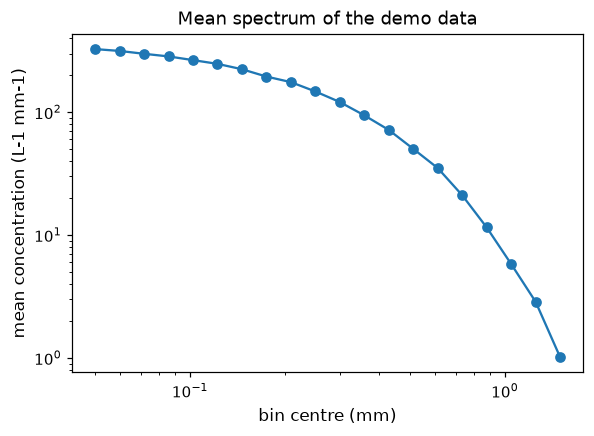

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ds["bin_mid"], ds["conc"].mean("time"), marker="o")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("bin centre (mm)")
ax.set_ylabel("mean concentration (L-1 mm-1)")
ax.set_title("Mean spectrum of the demo data")
plt.show()

The concentration falls with size, as the demo was built to. In a real file, a spectrum
that rises again at the largest sizes, or an empty bin in the middle, is worth asking about.

The next cell plots the total concentration, summed over the bins, second by second.

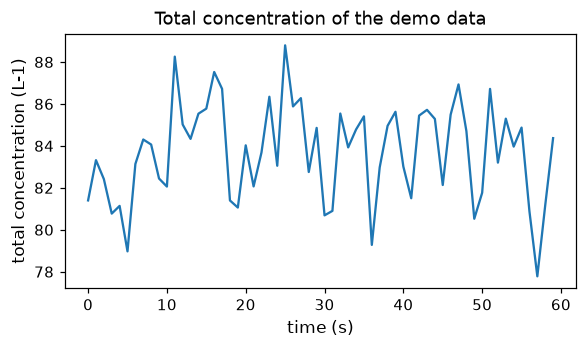

In [9]:
total = (ds["conc"] * bin_width_mm).sum("bin")

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(ds["time"], total)
ax.set_xlabel("time (s)")
ax.set_ylabel("total concentration (L-1)")
ax.set_title("Total concentration of the demo data")
plt.show()

The total changes only by counting noise, because the demo has no cloud in it. With your
own run, set this series beside what you know of the flight: a total that is high where there
was no cloud, or zero where there was, is the first thing to raise with the assistant.

## What to try next

- [01_validate_against_a_product](../3_validation/01_validate_against_a_product.ipynb): the next
  notebook, comparing a product with a reference.
- the notebooks in
  `2_processing/`: running other probes, whole campaigns, your own processing rules and
  reproducible runs.
- [01_find_stuck_diodes](../5_data_quality/01_find_stuck_diodes.ipynb) and the rest of
  `5_data_quality/`: the checks to run on your own data before quoting a number.
- [06_provenance](../7_analysis_and_outputs/06_provenance.ipynb): reading what made a file.
- `docs/06-configuration.md`: every line of the settings file, and what it refuses.